In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

%matplotlib inline

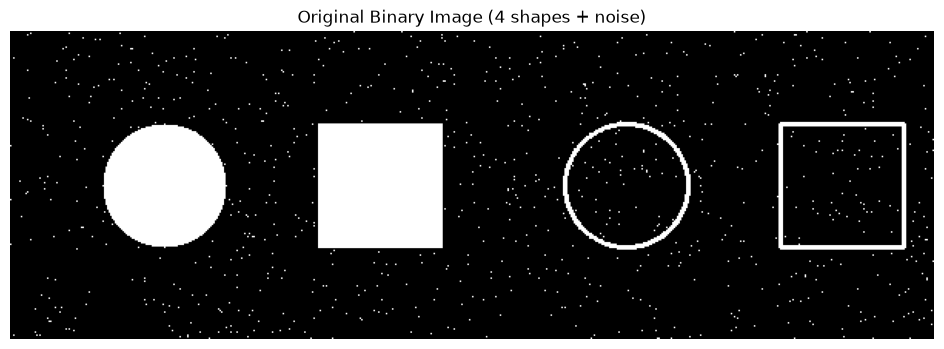

In [5]:
# Create a binary image with shapes and noise
image = np.zeros((200, 600), dtype=np.uint8)
cv2.circle(image, (100, 100), 40, 255, -1)              # Solid circle (filled) - radius=40
cv2.rectangle(image, (200, 60), (280, 140), 255, -1)    # Solid rectangle (filled) - start & end points= (200, 60), (280, 140)
cv2.circle(image, (400, 100), 40, 255, 2)               # Hollow circle (outline)
cv2.rectangle(image, (500, 60), (580, 140), 255, 2)     # Hollow rectangle (outline)

# Add small noise (1000 random white pixels)
np.random.seed(0)
for _ in range(1000):
    x, y = np.random.randint(0, 600), np.random.randint(0, 200)
    image[y, x] = 255

plt.figure(figsize=(12, 4))
plt.imshow(image, cmap='gray')
plt.title('Original Binary Image (4 shapes + noise)')
plt.axis('off')
plt.show()

In [6]:
kernel = np.ones((5, 5), np.uint8)
print("Square kernel (5×5):")
print(kernel)

Square kernel (5×5):
[[1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]
 [1 1 1 1 1]]


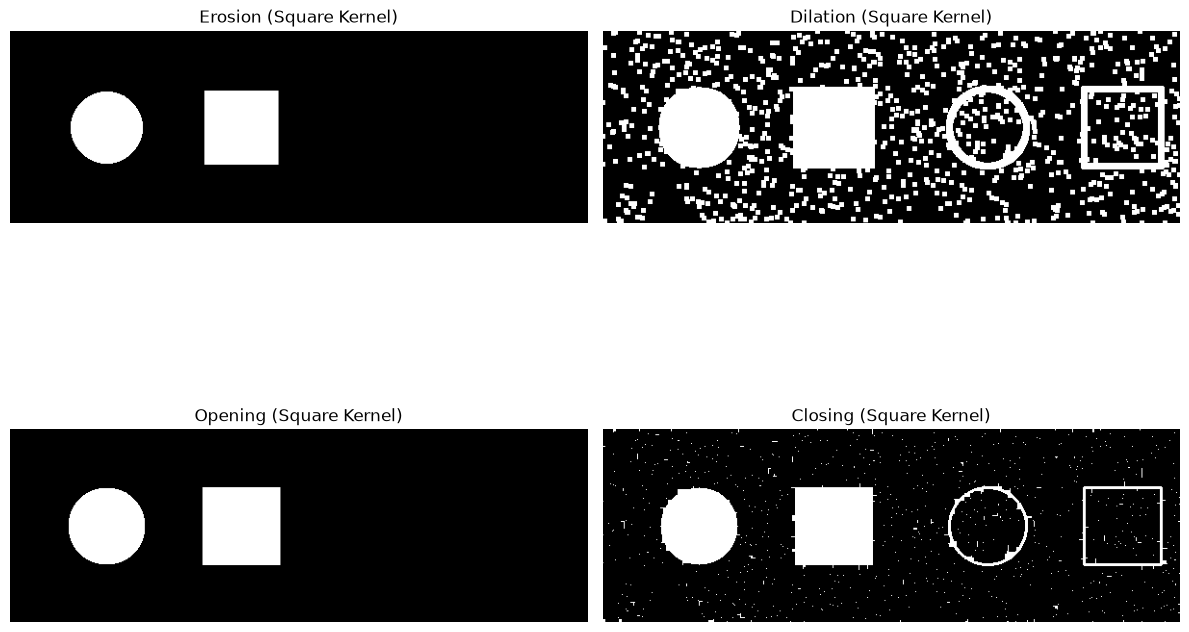

In [7]:
erosion_sq = cv2.erode(image, kernel, iterations=1)
dilation_sq = cv2.dilate(image, kernel, iterations=1)
opening_sq = cv2.morphologyEx(image, cv2.MORPH_OPEN, kernel)
closing_sq = cv2.morphologyEx(image, cv2.MORPH_CLOSE, kernel)

plt.figure(figsize=(12, 10))

plt.subplot(2, 2, 1)
plt.imshow(erosion_sq, cmap='gray')
plt.title('Erosion (Square Kernel)')
plt.axis('off')

plt.subplot(2, 2, 2)
plt.imshow(dilation_sq, cmap='gray')
plt.title('Dilation (Square Kernel)')
plt.axis('off')

plt.subplot(2, 2, 3)
plt.imshow(opening_sq, cmap='gray')
plt.title('Opening (Square Kernel)')
plt.axis('off')

plt.subplot(2, 2, 4)
plt.imshow(closing_sq, cmap='gray')
plt.title('Closing (Square Kernel)')
plt.axis('off')

plt.tight_layout()
plt.show()

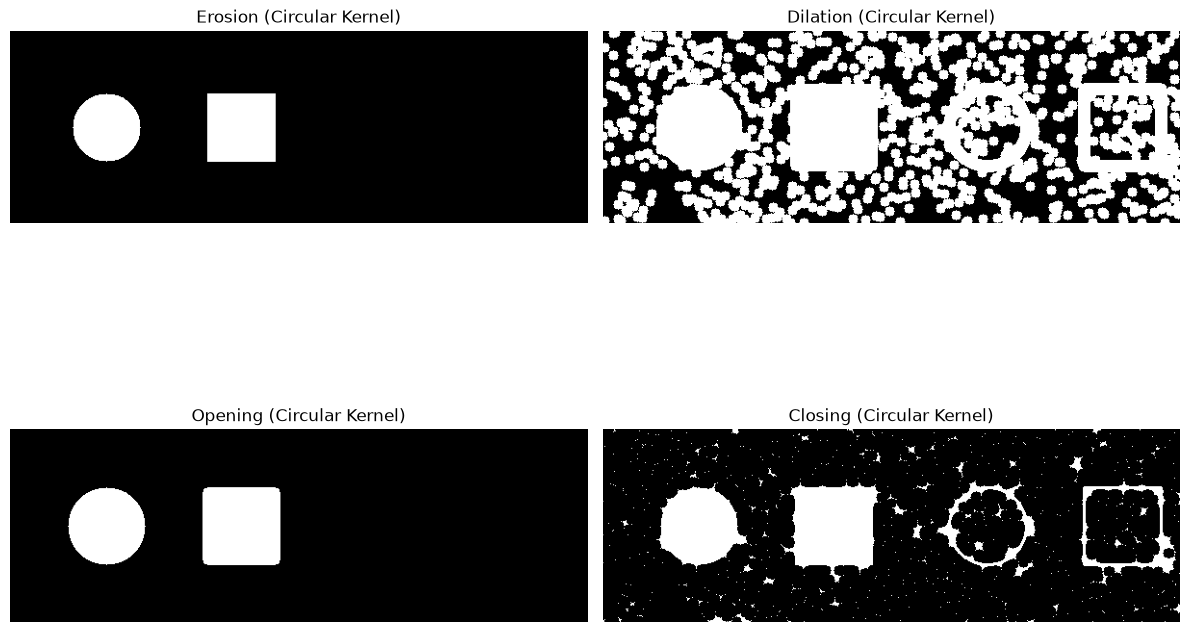

In [8]:
def circular_structuring_element(radius):
    """Creates a binary circular structuring element (exact circle)"""
    size = 2 * radius + 1                    # Ensure kernel size is odd
    kernel = np.zeros((size, size), dtype=np.uint8)
    cv2.circle(kernel, (radius, radius), radius, 1, -1)  # Draw filled circle
    return kernel

# Define radius
radius = 5
circle_kernel = circular_structuring_element(radius)
erosion_circ = cv2.erode(image, circle_kernel, iterations=1)
dilation_circ = cv2.dilate(image, circle_kernel, iterations=1)
opening_circ = cv2.morphologyEx(image, cv2.MORPH_OPEN, circle_kernel)
closing_circ = cv2.morphologyEx(image, cv2.MORPH_CLOSE, circle_kernel)

plt.figure(figsize=(12, 10))

plt.subplot(2, 2, 1)
plt.imshow(erosion_circ, cmap='gray')
plt.title('Erosion (Circular Kernel)')
plt.axis('off')

plt.subplot(2, 2, 2)
plt.imshow(dilation_circ, cmap='gray')
plt.title('Dilation (Circular Kernel)')
plt.axis('off')

plt.subplot(2, 2, 3)
plt.imshow(opening_circ, cmap='gray')
plt.title('Opening (Circular Kernel)')
plt.axis('off')

plt.subplot(2, 2, 4)
plt.imshow(closing_circ, cmap='gray')
plt.title('Closing (Circular Kernel)')
plt.axis('off')

plt.tight_layout()
plt.show()